# Traffic Flow Prediction in Urban Areas
Implementation of the 2-layer neural network from *Machine Learning for Traffic Flow Prediction in Urban Areas* (Huang & Zhou, 2021).

The model predicts road congestion level (`0` = clear road to `4` = heavy traffic) from three inputs:
- `road`: road segment ID (`0` to `34`)
- `day`: day of the week (`1` = Monday to `7` = Sunday)
- `hour`: hour of the day (`0` to `23`)

## 1. Imports and Setup

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline

SEED = 42
START_DATE = "2024-03-04"
NUM_WEEKS = 4
NUM_ROADS = 35
NUM_CLASSES = 5
BATCH_SIZE = 1000

LEVEL_COLORS = ["green", "orange", "red", "darkred", "black"]
np.random.seed(SEED)

## 2. Generate Traffic Dataset
Simulates 4 weeks of hourly speed data (in mph) across 35 road segments with morning and evening rush-hour patterns and weekday/weekend differences.

In [2]:
def generate_traffic_data(num_roads=NUM_ROADS, num_weeks=NUM_WEEKS, start_date=START_DATE, seed=SEED):
    rng = np.random.default_rng(seed)
    dates = pd.date_range(start_date, periods=7 * num_weeks, freq="D")
    hours = np.arange(24)

    # create road names and coordinates for plotting the grid
    num_avenues = max(2, num_roads // 3)
    names = ["Fifth Avenue", "Park Avenue"]
    names += [f"Avenue {i}" for i in range(1, num_avenues - 1)]
    names += [f"Street {i}" for i in range(1, num_roads - len(names) + 1)]
    names = names[:num_roads]

    theta = np.deg2rad(29.0)
    rot = np.array([[np.cos(theta), -np.sin(theta)], [np.sin(theta), np.cos(theta)]])
    lat0, lon0 = 40.76, -73.98
    lat_list, lon_list = [], []

    for i in range(num_roads):
        if i < num_avenues:
            x = 0.9 * i
            seg = np.array([[x, x], [rng.uniform(0.0, 2.0), rng.uniform(6.0, 10.0)]])
        else:
            y = rng.uniform(0.5, 9.5)
            seg = np.array([[0.0, rng.uniform(3.0, 0.9 * num_avenues)], [y, y]])
        xy = rot @ seg
        lat_list.append(list(lat0 + 0.009 * xy[1]))
        lon_list.append(list(lon0 + 0.012 * xy[0]))

    roads_df = pd.DataFrame({
        "link_id": np.arange(1000, 1000 + num_roads),
        "name": names,
        "lat": lat_list,
        "lon": lon_list
    })

    # day of week traffic factors (Friday busiest, weekend lightest)
    weekday_factor = {1: 1.00, 2: 1.00, 3: 1.00, 4: 1.05, 5: 1.20, 6: 0.70, 7: 0.50}
    rows = []

    for link_id in roads_df["link_id"]:
        free_flow = rng.uniform(18, 45)
        amp = rng.uniform(0.25, 0.65)
        am_share = rng.uniform(0.2, 1.0)

        # daily traffic peaks around 8:30am, 1:00pm, and 5:30pm
        daily_curve = (
            am_share * np.exp(-((hours - 8.5) ** 2) / (2 * 1.5 ** 2))
            + (1.2 - am_share) * np.exp(-((hours - 17.5) ** 2) / (2 * 2.0 ** 2))
            + 0.5 * np.exp(-((hours - 13.0) ** 2) / (2 * 2.5 ** 2))
        )

        for d in dates:
            f = weekday_factor[d.isoweekday()] * (1 + rng.normal(0, 0.05))
            congestion = np.clip(amp * daily_curve * f, 0.0, 0.92)
            speed = np.maximum(free_flow * (1 - congestion) + rng.normal(0, 0.8, 24), 1.5)
            rows.append(pd.DataFrame({
                "link_id": link_id,
                "date": d,
                "hour": hours,
                "speed": speed
            }))

    hourly_df = pd.concat(rows, ignore_index=True)
    return hourly_df, roads_df

hourly_df, roads_df = generate_traffic_data()
print(f"Total hourly records: {len(hourly_df)}")
hourly_df.head()

Total hourly records: 23520


,link_id,date,hour,speed
0,1000,2024-03-04,0,23.058217
1,1000,2024-03-04,1,24.191438
2,1000,2024-03-04,2,23.906752
3,1000,2024-03-04,3,24.334757
4,1000,2024-03-04,4,23.353874


## 3. Data Preprocessing and Congestion Labelling
For each road, we standardize its hourly speeds ($z = \frac{\text{speed} - \mu}{\sigma}$) and find the difference from that road's maximum speed ($\text{gap} = z_{\max} - z$). Each road hour is then assigned a congestion level from `0` to `4` based on how many standard deviations below peak speed it is.

In [3]:
def assign_congestion_levels(df):
    levels = np.zeros(len(df), dtype=int)

    for road_id, group in df.groupby("road"):
        speeds = group["speed"].to_numpy(dtype=float)
        mean_speed = np.mean(speeds)
        std_speed = np.std(speeds)
        if std_speed == 0 or np.isnan(std_speed):
            std_speed = 1.0

        z = (speeds - mean_speed) / std_speed
        gap = np.max(z) - z

        road_levels = np.zeros(len(speeds), dtype=int)
        for i, g in enumerate(gap):
            if g <= 2.0:
                road_levels[i] = 0
            elif g <= 3.0:
                road_levels[i] = 1
            elif g <= 4.0:
                road_levels[i] = 2
            elif g <= 5.0:
                road_levels[i] = 3
            else:
                road_levels[i] = 4

        levels[group.index] = road_levels

    return levels


def prepare_dataset(hourly_df, roads_df):
    df = hourly_df.dropna(subset=["speed"]).copy()
    df["date"] = pd.to_datetime(df["date"])
    df["hour"] = df["hour"].astype(int)
    start = pd.Timestamp(START_DATE)

    unique_links = sorted(df["link_id"].unique())[:NUM_ROADS]
    df = df[df["link_id"].isin(unique_links)].copy()

    # map link_id to 0..34
    road_map = {lid: i for i, lid in enumerate(unique_links)}
    df["road"] = df["link_id"].map(road_map).astype(int)

    name_map = dict(zip(roads_df["link_id"], roads_df["name"]))
    road_names = [str(name_map[lid]) for lid in unique_links]

    df["day"] = df["date"].dt.dayofweek + 1
    df["week"] = (df["date"] - start).dt.days // 7
    df = df[(df["week"] >= 0) & (df["week"] < NUM_WEEKS)].reset_index(drop=True)

    df["level"] = assign_congestion_levels(df)
    df = df.sort_values(["week", "road", "day", "hour"]).reset_index(drop=True)
    return df, road_names

df, road_names = prepare_dataset(hourly_df, roads_df)
print("Class counts:")
print(df["level"].value_counts().sort_index())
df.head()

Class counts:
level
0    15096
1     5793
2     2338
3      286
4        7
Name: count, dtype: int64


,link_id,date,hour,speed,road,day,week,level
0,1000,2024-03-04,0,23.058217,0,1,0,0
1,1000,2024-03-04,1,24.191438,0,1,0,0
2,1000,2024-03-04,2,23.906752,0,1,0,0
3,1000,2024-03-04,3,24.334757,0,1,0,0
4,1000,2024-03-04,4,23.353874,0,1,0,0


## 4. Train/Validation Split and Feature Encoding
The first 3 weeks are used for training and the 4th week is held out for validation. We support both the paper's 3 standardized features (`[road, day, hour]`) and one-hot encoded features.

In [4]:
val_week = NUM_WEEKS - 1
train_df = df[df["week"] < val_week].copy()
val_df = df[df["week"] == val_week].copy()

print(f"Train samples: {len(train_df)}, Validation samples: {len(val_df)}")

# compute mean and std on training features for standardization
raw_train_features = train_df[["road", "day", "hour"]].to_numpy(dtype=float)
TRAIN_MEAN = np.mean(raw_train_features, axis=0)
TRAIN_STD = np.std(raw_train_features, axis=0)


def encode_features(roads, days, hours, mode="paper"):
    roads = np.asarray(roads, dtype=int)
    days = np.asarray(days, dtype=int)
    hours = np.asarray(hours, dtype=int)

    if mode == "paper":
        raw = np.column_stack([roads, days, hours]).astype(float)
        return (raw - TRAIN_MEAN) / TRAIN_STD
    else:
        # one-hot encoding for road (35), day (7), and hour (24)
        road_oh = np.eye(NUM_ROADS)[roads]
        day_oh = np.eye(7)[days - 1]
        hour_oh = np.eye(24)[hours]
        return np.hstack([road_oh, day_oh, hour_oh])

Train samples: 17640, Validation samples: 5880


## 5. Neural Network Implementation (NumPy)
Two-layer neural network with a sigmoid hidden layer, softmax output layer, and cross-entropy loss.

In [5]:
def sigmoid(z):
    z = np.clip(z, -500.0, 500.0)
    return 1.0 / (1.0 + np.exp(-z))


def softmax(z):
    z_shifted = z - np.max(z, axis=1, keepdims=True)
    exp_z = np.exp(z_shifted)
    return exp_z / np.sum(exp_z, axis=1, keepdims=True)


def cross_entropy_loss(y_prob, y_true_onehot):
    return float(-np.mean(np.sum(y_true_onehot * np.log(y_prob + 1e-12), axis=1)))


def init_network(n_in, n_hidden, n_out, seed=SEED):
    rng = np.random.default_rng(seed)
    W1 = rng.normal(0.0, np.sqrt(2.0 / (n_in + n_hidden)), size=(n_in, n_hidden))
    b1 = np.zeros(n_hidden)
    W2 = rng.normal(0.0, np.sqrt(2.0 / (n_hidden + n_out)), size=(n_hidden, n_out))
    b2 = np.zeros(n_out)
    return {"W1": W1, "b1": b1, "W2": W2, "b2": b2}


def forward(model, X):
    # hidden layer
    z1 = X @ model["W1"] + model["b1"]
    a = sigmoid(z1)
    # output layer
    z2 = a @ model["W2"] + model["b2"]
    y_hat = softmax(z2)
    return a, y_hat


def predict(model, X):
    _, y_hat = forward(model, X)
    return np.argmax(y_hat, axis=1)


def backward(model, X_batch, Y_batch_onehot):
    batch_size = len(X_batch)
    a, y_hat = forward(model, X_batch)
    loss = cross_entropy_loss(y_hat, Y_batch_onehot)

    # output layer gradients
    dz2 = (y_hat - Y_batch_onehot) / batch_size
    dW2 = a.T @ dz2
    db2 = np.sum(dz2, axis=0)

    # hidden layer gradients
    da = dz2 @ model["W2"].T
    dz1 = da * a * (1.0 - a)
    dW1 = X_batch.T @ dz1
    db1 = np.sum(dz1, axis=0)

    grads = {"W1": dW1, "b1": db1, "W2": dW2, "b2": db2}
    return loss, grads


def update_parameters(model, grads, lr):
    model["W1"] -= lr * grads["W1"]
    model["b1"] -= lr * grads["b1"]
    model["W2"] -= lr * grads["W2"]
    model["b2"] -= lr * grads["b2"]

## 6. Training, Evaluation, and Plotting Functions

In [6]:
def train_model(model, X_train, y_train, X_val, y_val, episodes=30000, lr=3.0, batch_size=BATCH_SIZE, print_every=5000):
    Y_train_oh = np.eye(NUM_CLASSES)[y_train]
    Y_val_oh = np.eye(NUM_CLASSES)[y_val]

    n = len(X_train)
    rng = np.random.default_rng(SEED)
    order = rng.permutation(n)
    ptr = 0

    history = {"episode": [], "train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

    def log_step(ep):
        _, p_tr = forward(model, X_train)
        _, p_va = forward(model, X_val)
        history["episode"].append(ep)
        history["train_loss"].append(cross_entropy_loss(p_tr, Y_train_oh))
        history["train_acc"].append(float(np.mean(np.argmax(p_tr, axis=1) == y_train)))
        history["val_loss"].append(cross_entropy_loss(p_va, Y_val_oh))
        history["val_acc"].append(float(np.mean(np.argmax(p_va, axis=1) == y_val)))

    log_step(0)

    for ep in range(1, episodes + 1):
        if ptr >= n:
            order = rng.permutation(n)
            ptr = 0
        idx = order[ptr : ptr + batch_size]
        ptr += batch_size

        _, grads = backward(model, X_train[idx], Y_train_oh[idx])
        update_parameters(model, grads, lr)

        if ep % 100 == 0 or ep == episodes:
            log_step(ep)

        if ep % print_every == 0 or ep == episodes:
            print(f"Episode {ep:5d} | Loss: {history['train_loss'][-1]:.4f} | "
                  f"Train Acc: {history['train_acc'][-1]:.3f} | Val Acc: {history['val_acc'][-1]:.3f}")

    return history


def get_confusion_matrix(y_true, y_pred, k=NUM_CLASSES):
    cm = np.zeros((k, k), dtype=int)
    for t, p in zip(y_true, y_pred):
        cm[t, p] += 1
    return cm


def evaluate_model(model, X, y, label="Validation"):
    preds = predict(model, X)
    acc = np.mean(preds == y)
    within_one = np.mean(np.abs(preds - y) <= 1)
    cm = get_confusion_matrix(y, preds)

    print(f"\n--- {label} Results ---")
    print(f"Accuracy: {acc:.3f}")
    print(f"Within +/- 1 level: {within_one:.3f}")
    cm_df = pd.DataFrame(
        cm,
        index=[f"True {i}" for i in range(NUM_CLASSES)],
        columns=[f"Pred {j}" for j in range(NUM_CLASSES)]
    )
    print(cm_df)
    return cm

In [7]:
def plot_results(model, history, cm, mode="paper", out_dir="traffic_outputs"):
    os.makedirs(out_dir, exist_ok=True)

    # 1. Training curves
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(history["episode"], history["train_acc"], label="Train")
    ax[0].plot(history["episode"], history["val_acc"], label="Validation", linestyle="--")
    ax[0].set(title="Accuracy vs Episodes", xlabel="Episodes", ylabel="Accuracy", ylim=(0, 1))
    ax[0].legend()
    ax[0].grid(alpha=0.3)

    ax[1].plot(history["episode"], history["train_loss"], label="Train")
    ax[1].plot(history["episode"], history["val_loss"], label="Validation", linestyle="--")
    ax[1].set(title="Loss vs Episodes", xlabel="Episodes", ylabel="Cross-Entropy Loss")
    ax[1].legend()
    ax[1].grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(os.path.join(out_dir, "training_curves.png"), dpi=150)
    plt.show()

    # 2. Road congestion profiles (Friday hourly + 5 PM across the week)
    spread = val_df.groupby("road")["level"].std().fillna(0).sort_values(ascending=False)
    road_a, road_b = int(spread.index[0]), int(spread.index[1])

    fig, ax = plt.subplots(1, 3, figsize=(15, 4))
    for a, r in zip(ax[:2], [road_a, road_b]):
        hrs = np.arange(24)
        X_day = encode_features(np.full(24, r), np.full(24, 5), hrs, mode=mode)
        pred_day = predict(model, X_day)
        actual_day = (
            val_df[(val_df["road"] == r) & (val_df["day"] == 5)]
            .set_index("hour")["level"]
            .reindex(hrs)
            .to_numpy(float)
        )
        a.step(hrs, pred_day, where="mid", label="Predicted")
        a.step(hrs, actual_day, where="mid", label="Actual")
        a.set(title=f"{road_names[r]} (Friday)", xlabel="Hour", ylabel="Level", ylim=(-0.3, 4.3))
        a.legend()
        a.grid(alpha=0.3)

    days = np.arange(1, 8)
    X_wk = encode_features(np.full(7, road_a), days, np.full(7, 17), mode=mode)
    pred_wk = predict(model, X_wk)
    actual_wk = (
        val_df[(val_df["road"] == road_a) & (val_df["hour"] == 17)]
        .set_index("day")["level"]
        .reindex(days)
        .to_numpy(float)
    )
    ax[2].step(days, pred_wk, where="mid", label="Predicted")
    ax[2].step(days, actual_wk, where="mid", label="Actual")
    ax[2].set(title=f"{road_names[road_a]} at 17:00 (Mon-Sun)", xlabel="Day", ylabel="Level", ylim=(-0.3, 4.3))
    ax[2].legend()
    ax[2].grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(os.path.join(out_dir, "road_profiles.png"), dpi=150)
    plt.show()

    # 3. Street map (Friday 15:00)
    link_ids = sorted(df["link_id"].unique())
    geom = roads_df.set_index("link_id")
    X_map = encode_features(np.arange(NUM_ROADS), np.full(NUM_ROADS, 5), np.full(NUM_ROADS, 15), mode=mode)
    pred_map = predict(model, X_map)
    actual_map = (
        val_df[(val_df["day"] == 5) & (val_df["hour"] == 15)]
        .set_index("road")["level"]
        .reindex(range(NUM_ROADS))
    )

    fig, ax = plt.subplots(1, 2, figsize=(12, 5.5), sharex=True, sharey=True)
    for i, lid in enumerate(link_ids):
        lat, lon = geom.loc[lid, "lat"], geom.loc[lid, "lon"]
        ax[0].plot(lon, lat, color=LEVEL_COLORS[int(pred_map[i])], lw=2.5)
        if not np.isnan(actual_map.iloc[i]):
            ax[1].plot(lon, lat, color=LEVEL_COLORS[int(actual_map.iloc[i])], lw=2.5)

    ax[0].set(title="Predicted Congestion (Fri 15:00)", xlabel="Longitude", ylabel="Latitude")
    ax[1].set(title="Actual Congestion (Fri 15:00)", xlabel="Longitude")
    for a in ax:
        a.set_aspect(1.0 / np.cos(np.deg2rad(40.75)))
        a.grid(alpha=0.2)
    handles = [plt.Line2D([0], [0], color=c, lw=3, label=f"Level {i}") for i, c in enumerate(LEVEL_COLORS)]
    ax[1].legend(handles=handles, loc="best")
    fig.tight_layout()
    fig.savefig(os.path.join(out_dir, "congestion_map.png"), dpi=150)
    plt.show()

    # 4. Confusion matrix plot
    fig, a = plt.subplots(figsize=(5, 4.5))
    im = a.imshow(cm, cmap="Blues")
    a.set(
        xticks=range(NUM_CLASSES),
        yticks=range(NUM_CLASSES),
        xlabel="Predicted Level",
        ylabel="True Level",
        title="Validation Confusion Matrix"
    )
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            color = "white" if cm[i, j] > cm.max() / 2 else "black"
            a.text(j, i, str(cm[i, j]), ha="center", va="center", color=color)
    fig.colorbar(im)
    fig.tight_layout()
    fig.savefig(os.path.join(out_dir, "confusion_matrix.png"), dpi=150)
    plt.show()

## 7. Run Model 1: Paper Baseline (3 Standardized Inputs, 4 Hidden Neurons)

Episode  5000 | Loss: 0.5335 | Train Acc: 0.771 | Val Acc: 0.775
Episode 10000 | Loss: 0.5325 | Train Acc: 0.768 | Val Acc: 0.772
Episode 15000 | Loss: 0.5309 | Train Acc: 0.768 | Val Acc: 0.771
Episode 20000 | Loss: 0.5327 | Train Acc: 0.768 | Val Acc: 0.772
Episode 25000 | Loss: 0.5301 | Train Acc: 0.768 | Val Acc: 0.772
Episode 30000 | Loss: 0.5296 | Train Acc: 0.770 | Val Acc: 0.774

--- Training Set Results ---
Accuracy: 0.770
Within +/- 1 level: 0.983
        Pred 0  Pred 1  Pred 2  Pred 3  Pred 4
True 0   10161    1075      81       0       0
True 1    1072    3013     264       0       0
True 2      64    1285     405       0       0
True 3       1     154      59       0       0
True 4       0       5       1       0       0

--- Validation Set Results ---
Accuracy: 0.774
Within +/- 1 level: 0.982
        Pred 0  Pred 1  Pred 2  Pred 3  Pred 4
True 0    3400     350      29       0       0
True 1     345    1014      85       0       0
True 2      20     425     139       0   

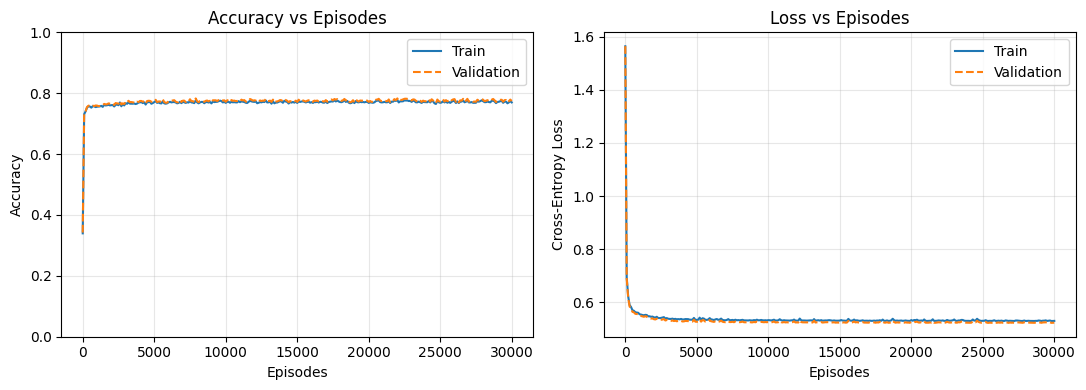

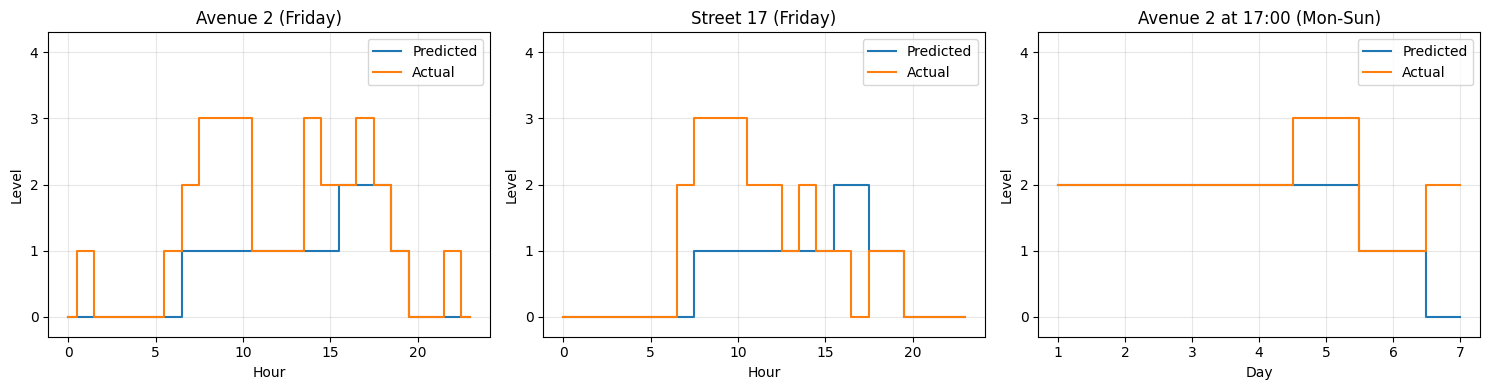

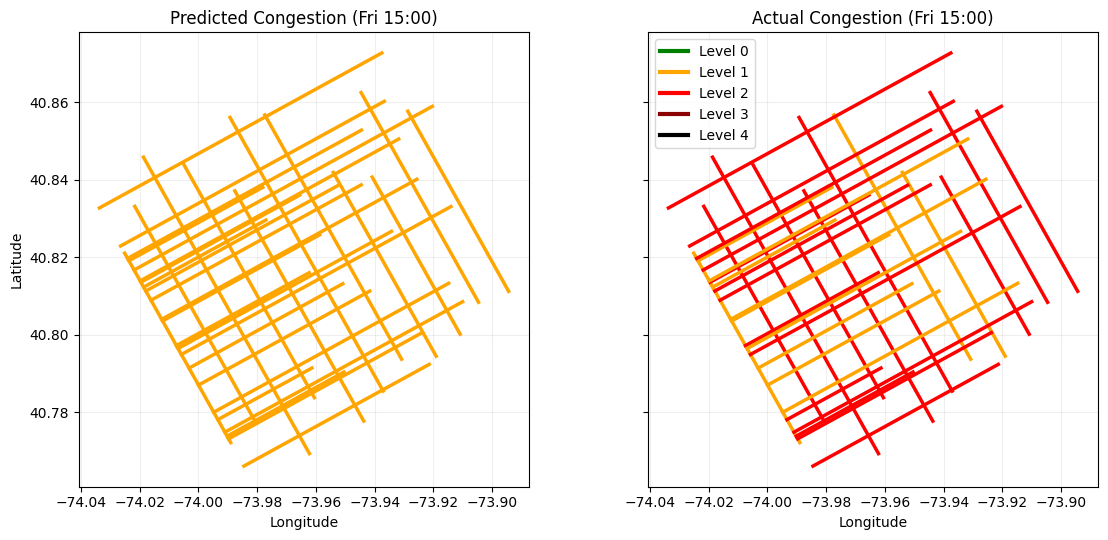

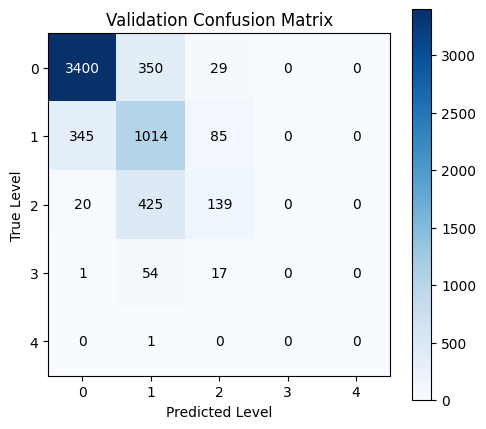

In [8]:
X_train_paper = encode_features(train_df["road"], train_df["day"], train_df["hour"], mode="paper")
y_train = train_df["level"].to_numpy(dtype=int)

X_val_paper = encode_features(val_df["road"], val_df["day"], val_df["hour"], mode="paper")
y_val = val_df["level"].to_numpy(dtype=int)

model_paper = init_network(n_in=3, n_hidden=4, n_out=NUM_CLASSES)
history_paper = train_model(model_paper, X_train_paper, y_train, X_val_paper, y_val, episodes=30000, lr=3.0)

evaluate_model(model_paper, X_train_paper, y_train, label="Training Set")
cm_paper = evaluate_model(model_paper, X_val_paper, y_val, label="Validation Set")
plot_results(model_paper, history_paper, cm_paper, mode="paper", out_dir="traffic_outputs")

## 8. Run Model 2: One-Hot Encoded Inputs (66 Inputs, 32 Hidden Neurons)

Episode  1000 | Loss: 0.4393 | Train Acc: 0.810 | Val Acc: 0.818
Episode  2000 | Loss: 0.4080 | Train Acc: 0.824 | Val Acc: 0.830
Episode  3000 | Loss: 0.3407 | Train Acc: 0.867 | Val Acc: 0.873
Episode  4000 | Loss: 0.2643 | Train Acc: 0.903 | Val Acc: 0.903
Episode  5000 | Loss: 0.2398 | Train Acc: 0.907 | Val Acc: 0.903
Episode  6000 | Loss: 0.2295 | Train Acc: 0.908 | Val Acc: 0.904

--- Training Set (One-Hot) Results ---
Accuracy: 0.908
Within +/- 1 level: 0.999
        Pred 0  Pred 1  Pred 2  Pred 3  Pred 4
True 0   10937     378       2       0       0
True 1     448    3613     279       9       0
True 2       3     315    1421      15       0
True 3       0       2     159      53       0
True 4       0       0       2       4       0

--- Validation Set (One-Hot) Results ---
Accuracy: 0.904
Within +/- 1 level: 0.999
        Pred 0  Pred 1  Pred 2  Pred 3  Pred 4
True 0    3632     146       0       1       0
True 1     163    1185      94       2       0
True 2       1     10

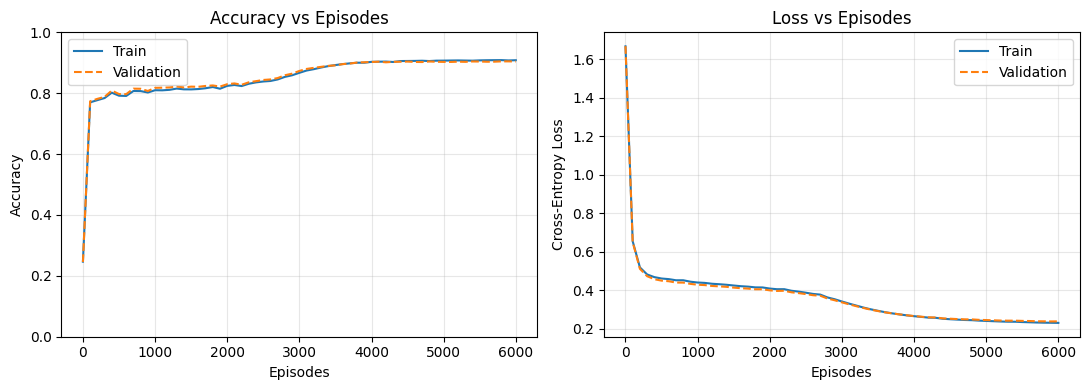

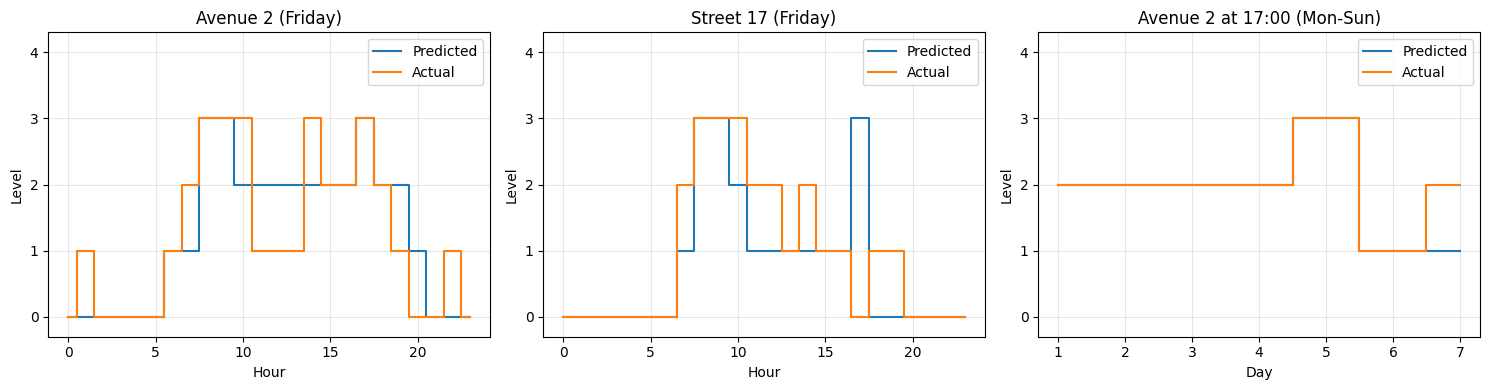

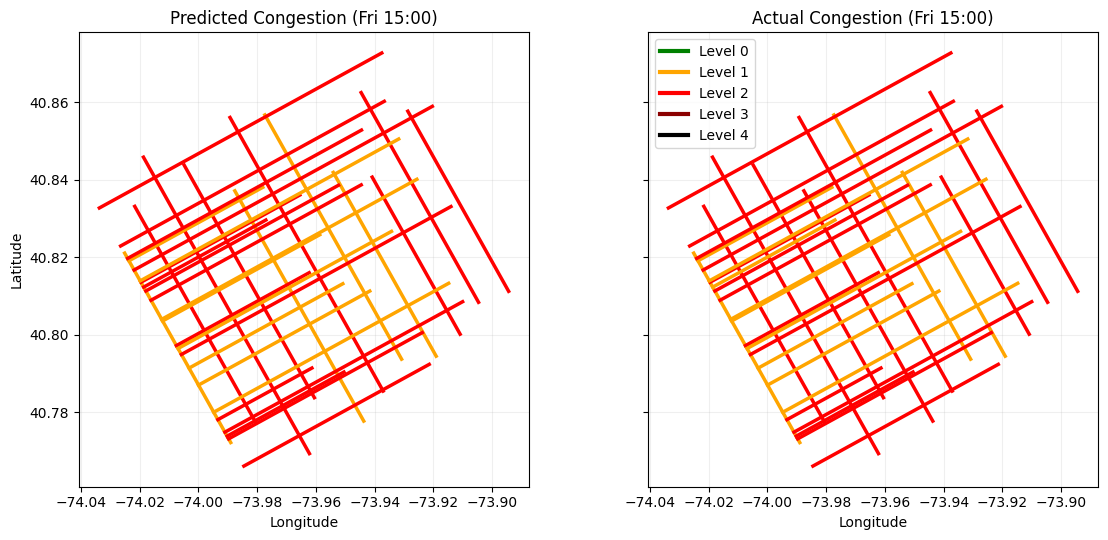

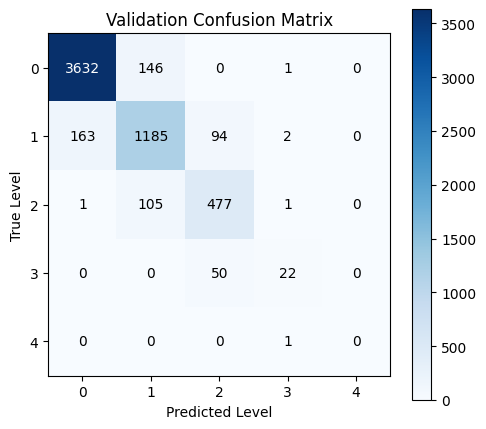

In [9]:
X_train_oh = encode_features(train_df["road"], train_df["day"], train_df["hour"], mode="onehot")
X_val_oh = encode_features(val_df["road"], val_df["day"], val_df["hour"], mode="onehot")

model_oh = init_network(n_in=X_train_oh.shape[1], n_hidden=32, n_out=NUM_CLASSES)
history_oh = train_model(model_oh, X_train_oh, y_train, X_val_oh, y_val, episodes=6000, lr=1.0, print_every=1000)

evaluate_model(model_oh, X_train_oh, y_train, label="Training Set (One-Hot)")
cm_oh = evaluate_model(model_oh, X_val_oh, y_val, label="Validation Set (One-Hot)")
plot_results(model_oh, history_oh, cm_oh, mode="onehot", out_dir="traffic_outputs_onehot")